# Figure 2 and Figure 3 panels

子图写到本目录的 `figures_fig2_fig3/`。页面规格与 `promoter/fig2.md`、`promoter/fig3.md` 一致。

- Figure 2 只用 fold 0：`best_mlp_gpu.pt` 是这一折的权重，一张切片整张在训练或验证里。
- Figure 3 用同一套权重在 H&E 上的预测。Spot 的颜色是捕获区内预测 L2 的多数类，不是另一个模型。

裁图和 fold 0 的分数表调用 `promoter/build_fig23.py`。单核收到 spot 的捕获区调用 `Hist2Pheno_pkg/nuclei_to_spots.py`。


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code"))
sys.path.insert(0, str(REPO / "code" / "Hist2Pheno_pkg"))
sys.path.insert(0, str(REPO / "promoter"))

import build_fig23 as fig23
from plotting_palettes import get_palette
from uni_label_cv_helpers import macro_auc_ovr
from nuclei_to_spots import nuclei_to_spots

DATA = REPO / "data"
OUT = REPO / "code" / "Hist2Pheno_pkg" / "dataset" / "figures_fig2_fig3"
OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "Liberation Sans",
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "axes.linewidth": 0.4,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

L2_PALETTE = get_palette("pancancer", "fine")
L12_PALETTE = get_palette("pancancer", "intermediate")
L1_PALETTE = get_palette("pancancer", "coarse")
TIER_PALETTE = {"L1": L1_PALETTE, "L12": L12_PALETTE, "L2": L2_PALETTE}

try:
    from IPython.display import Image, display
except ImportError:
    Image = None
    def display(obj):
        print(obj)


def save_fig(fig, stem):
    png = OUT / f"{stem}.png"
    pdf = OUT / f"{stem}.pdf"
    fig.savefig(png, dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(pdf, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(png)
    if Image is not None:
        display(Image(filename=str(png)))
    return png


## Figure 2a. Section is the hold-out group

每个格子是该验证折留出的整张切片数。灰色列是 fold 0。数字来自 `data/PanCancer/fold_plan.csv`，共 896 张切片。CRC 三张都在交叉验证里：P2CRC 是 fold 0，P1CRC 是 fold 1，P5CRC 是 fold 2。

fold 0 sections 182


fold,0,1,2,3,4
dataset,,,,,
Lung,5,5,5,5,5
Breast,1,1,0,0,0
CRC,1,1,1,0,0
HCC,8,7,7,7,7
PDAC,56,56,56,55,55
GIST,110,110,110,110,110
GBM,1,1,0,0,0


/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2a_section_split.png


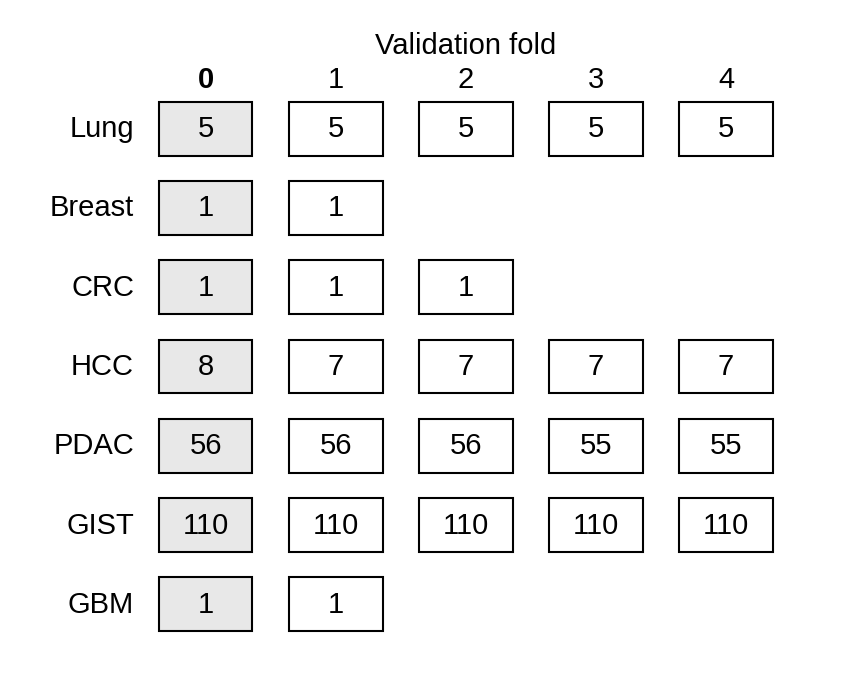

PosixPath('/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2a_section_split.png')

In [2]:
ORDER = ["Lung", "BRCA", "CRC", "HCC", "PDAC", "GIST", "GBM"]
SHOW = {"BRCA": "Breast"}

fold = pd.read_csv(DATA / "PanCancer/fold_plan.csv")
fold["fold"] = fold["fold"].astype(int)
counts = (
    fold.groupby(["dataset", "fold"]).size()
    .unstack("fold")
    .reindex(index=ORDER, columns=[0, 1, 2, 3, 4])
    .fillna(0)
    .astype(int)
)
counts.to_csv(OUT / "fig2a_section_counts.csv")
print("fold 0 sections", int(counts[0].sum()))
display(counts.rename(index=SHOW))

fig, ax = plt.subplots(figsize=(8.6 / 2.54, 6.8 / 2.54))
ax.set_xlim(-1.35, 4.7)
ax.set_ylim(len(ORDER) - 0.45, -1.25)
ax.axis("off")
ax.text(2, -1.05, "Validation fold", ha="center", va="center", fontsize=7)
for j, fold_id in enumerate(range(5)):
    ax.text(j, -0.62, str(fold_id), ha="center", va="center", fontsize=7,
            fontweight="bold" if fold_id == 0 else "regular")
for i, dataset in enumerate(ORDER):
    ax.text(-0.55, i, SHOW.get(dataset, dataset), ha="right", va="center", fontsize=7)
    for j, fold_id in enumerate(range(5)):
        value = int(counts.loc[dataset, fold_id])
        if value == 0:
            continue
        ax.add_patch(plt.Rectangle(
            (j - 0.36, i - 0.34), 0.72, 0.68,
            facecolor="#E8E8E8" if fold_id == 0 else "white",
            edgecolor="black", linewidth=0.5, zorder=2,
        ))
        ax.text(j, i, str(value), ha="center", va="center", fontsize=7, zorder=3)
save_fig(fig, "fig2a_section_split")

/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2a_sections_and_cells.png


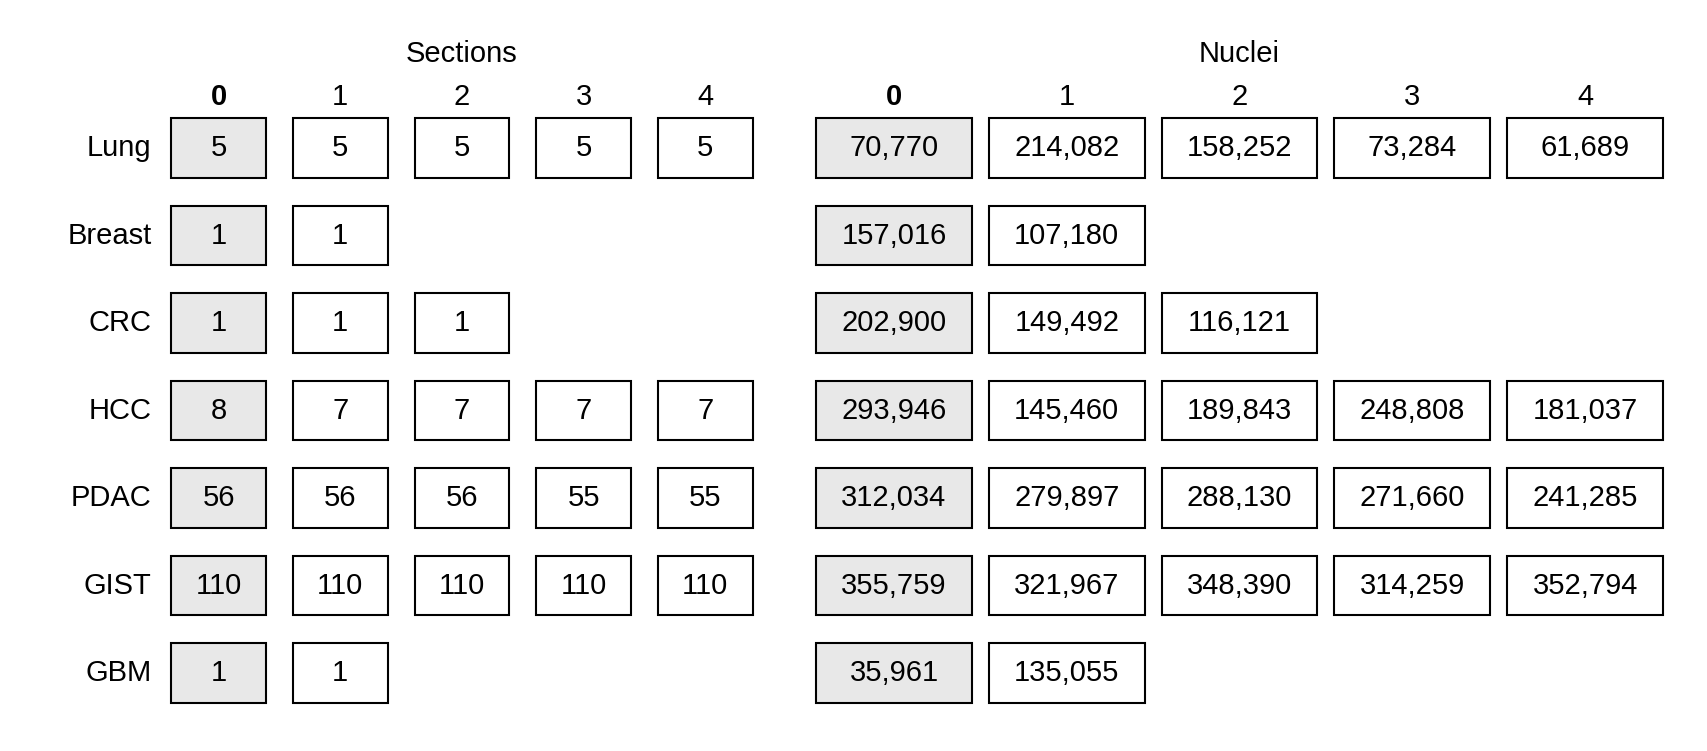

PosixPath('/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2a_sections_and_cells.png')

In [3]:
section_counts = (
    fold.groupby(["dataset", "fold"]).size()
    .unstack("fold")
    .reindex(index=ORDER, columns=[0, 1, 2, 3, 4])
    .fillna(0)
    .astype(int)
)
cell_counts = (
    fold.groupby(["dataset", "fold"])["n_keep"].sum()
    .unstack("fold")
    .reindex(index=ORDER, columns=[0, 1, 2, 3, 4])
    .fillna(0)
    .astype(int)
)

n = len(ORDER)
sec_w, nuc_w = 0.78, 1.28
sec_x = np.arange(5, dtype=float)
nuc_x = 5.55 + np.arange(5) * 1.42
box_h = 0.68
label_x = -0.55

fig, ax = plt.subplots(figsize=(18.0 / 2.54, 7.6 / 2.54))
ax.set_xlim(-1.55, nuc_x[-1] + nuc_w / 2 + 0.12)
ax.set_ylim(n - 0.45, -1.35)
ax.axis("off")
ax.text(sec_x.mean(), -1.08, "Sections", ha="center", va="center", fontsize=7)
ax.text(nuc_x.mean(), -1.08, "Nuclei", ha="center", va="center", fontsize=7)
for xs in (sec_x, nuc_x):
    for j, fold_id in enumerate(range(5)):
        ax.text(
            xs[j], -0.58, str(fold_id), ha="center", va="center", fontsize=7,
            fontweight="bold" if fold_id == 0 else "regular",
        )

def draw_block(table, xs, width, fmt):
    for i, dataset in enumerate(ORDER):
        for j, fold_id in enumerate(range(5)):
            value = int(table.loc[dataset, fold_id])
            if value == 0:
                continue
            ax.add_patch(plt.Rectangle(
                (xs[j] - width / 2, i - box_h / 2), width, box_h,
                facecolor="#E8E8E8" if fold_id == 0 else "white",
                edgecolor="black", linewidth=0.5, zorder=2,
            ))
            ax.text(xs[j], i, fmt(value), ha="center", va="center", fontsize=7, zorder=3)

for i, dataset in enumerate(ORDER):
    ax.text(label_x, i, SHOW.get(dataset, dataset), ha="right", va="center", fontsize=7)
draw_block(section_counts, sec_x, sec_w, str)
draw_block(cell_counts, nuc_x, nuc_w, "{:,}".format)
save_fig(fig, "fig2a_sections_and_cells")



## Figure 2a, continued. Kept cells and pathologist labels

上面把切片数和细胞核数画在同一张图里，行和折对齐。下面两张仍用同一套 5 折。

- 细胞数是 `fold_plan.csv` 的 `n_keep`：映射到 pan-cancer 标签后、这一折留出的细胞核数。
- 条形图是这些细胞核的病理标注，存在 `data/PanCancer/label_cache/`。`y_l1`、`y_l12`、`y` 分别是 L1、L12、L2。它们来自各队列单独训练时的标注，经 `celltype_pancancer` 映射后保留。条形是该折、该癌种内部的比例。纵轴上加粗的 0 是 fold 0。某一折没有这个癌种时，这一行留空。


fold,0,1,2,3,4
dataset,,,,,
Lung,70770,214082,158252,73284,61689
Breast,157016,107180,0,0,0
CRC,202900,149492,116121,0,0
HCC,293946,145460,189843,248808,181037
PDAC,312034,279897,288130,271660,241285
GIST,355759,321967,348390,314259,352794
GBM,35961,135055,0,0,0


/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2a_cell_counts.png


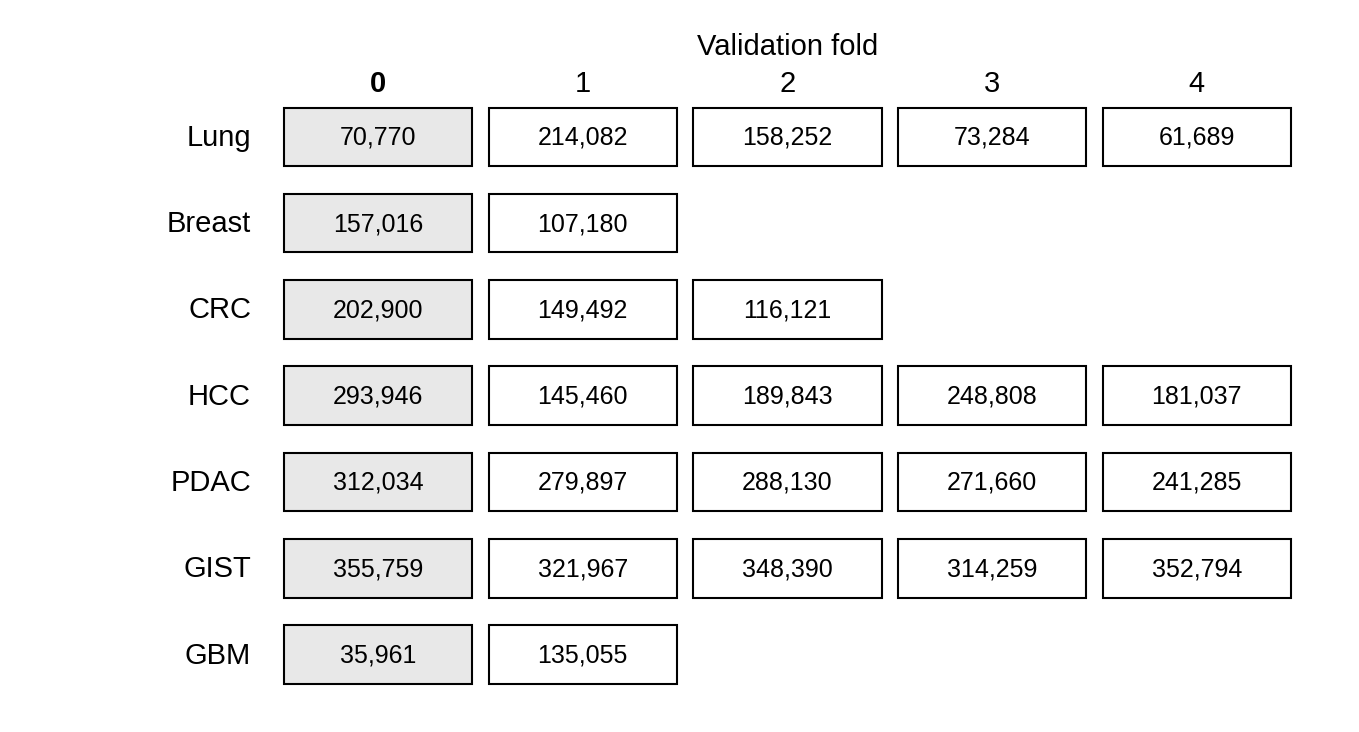

kept cells in cache 5,627,071
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2a_gt_composition.png


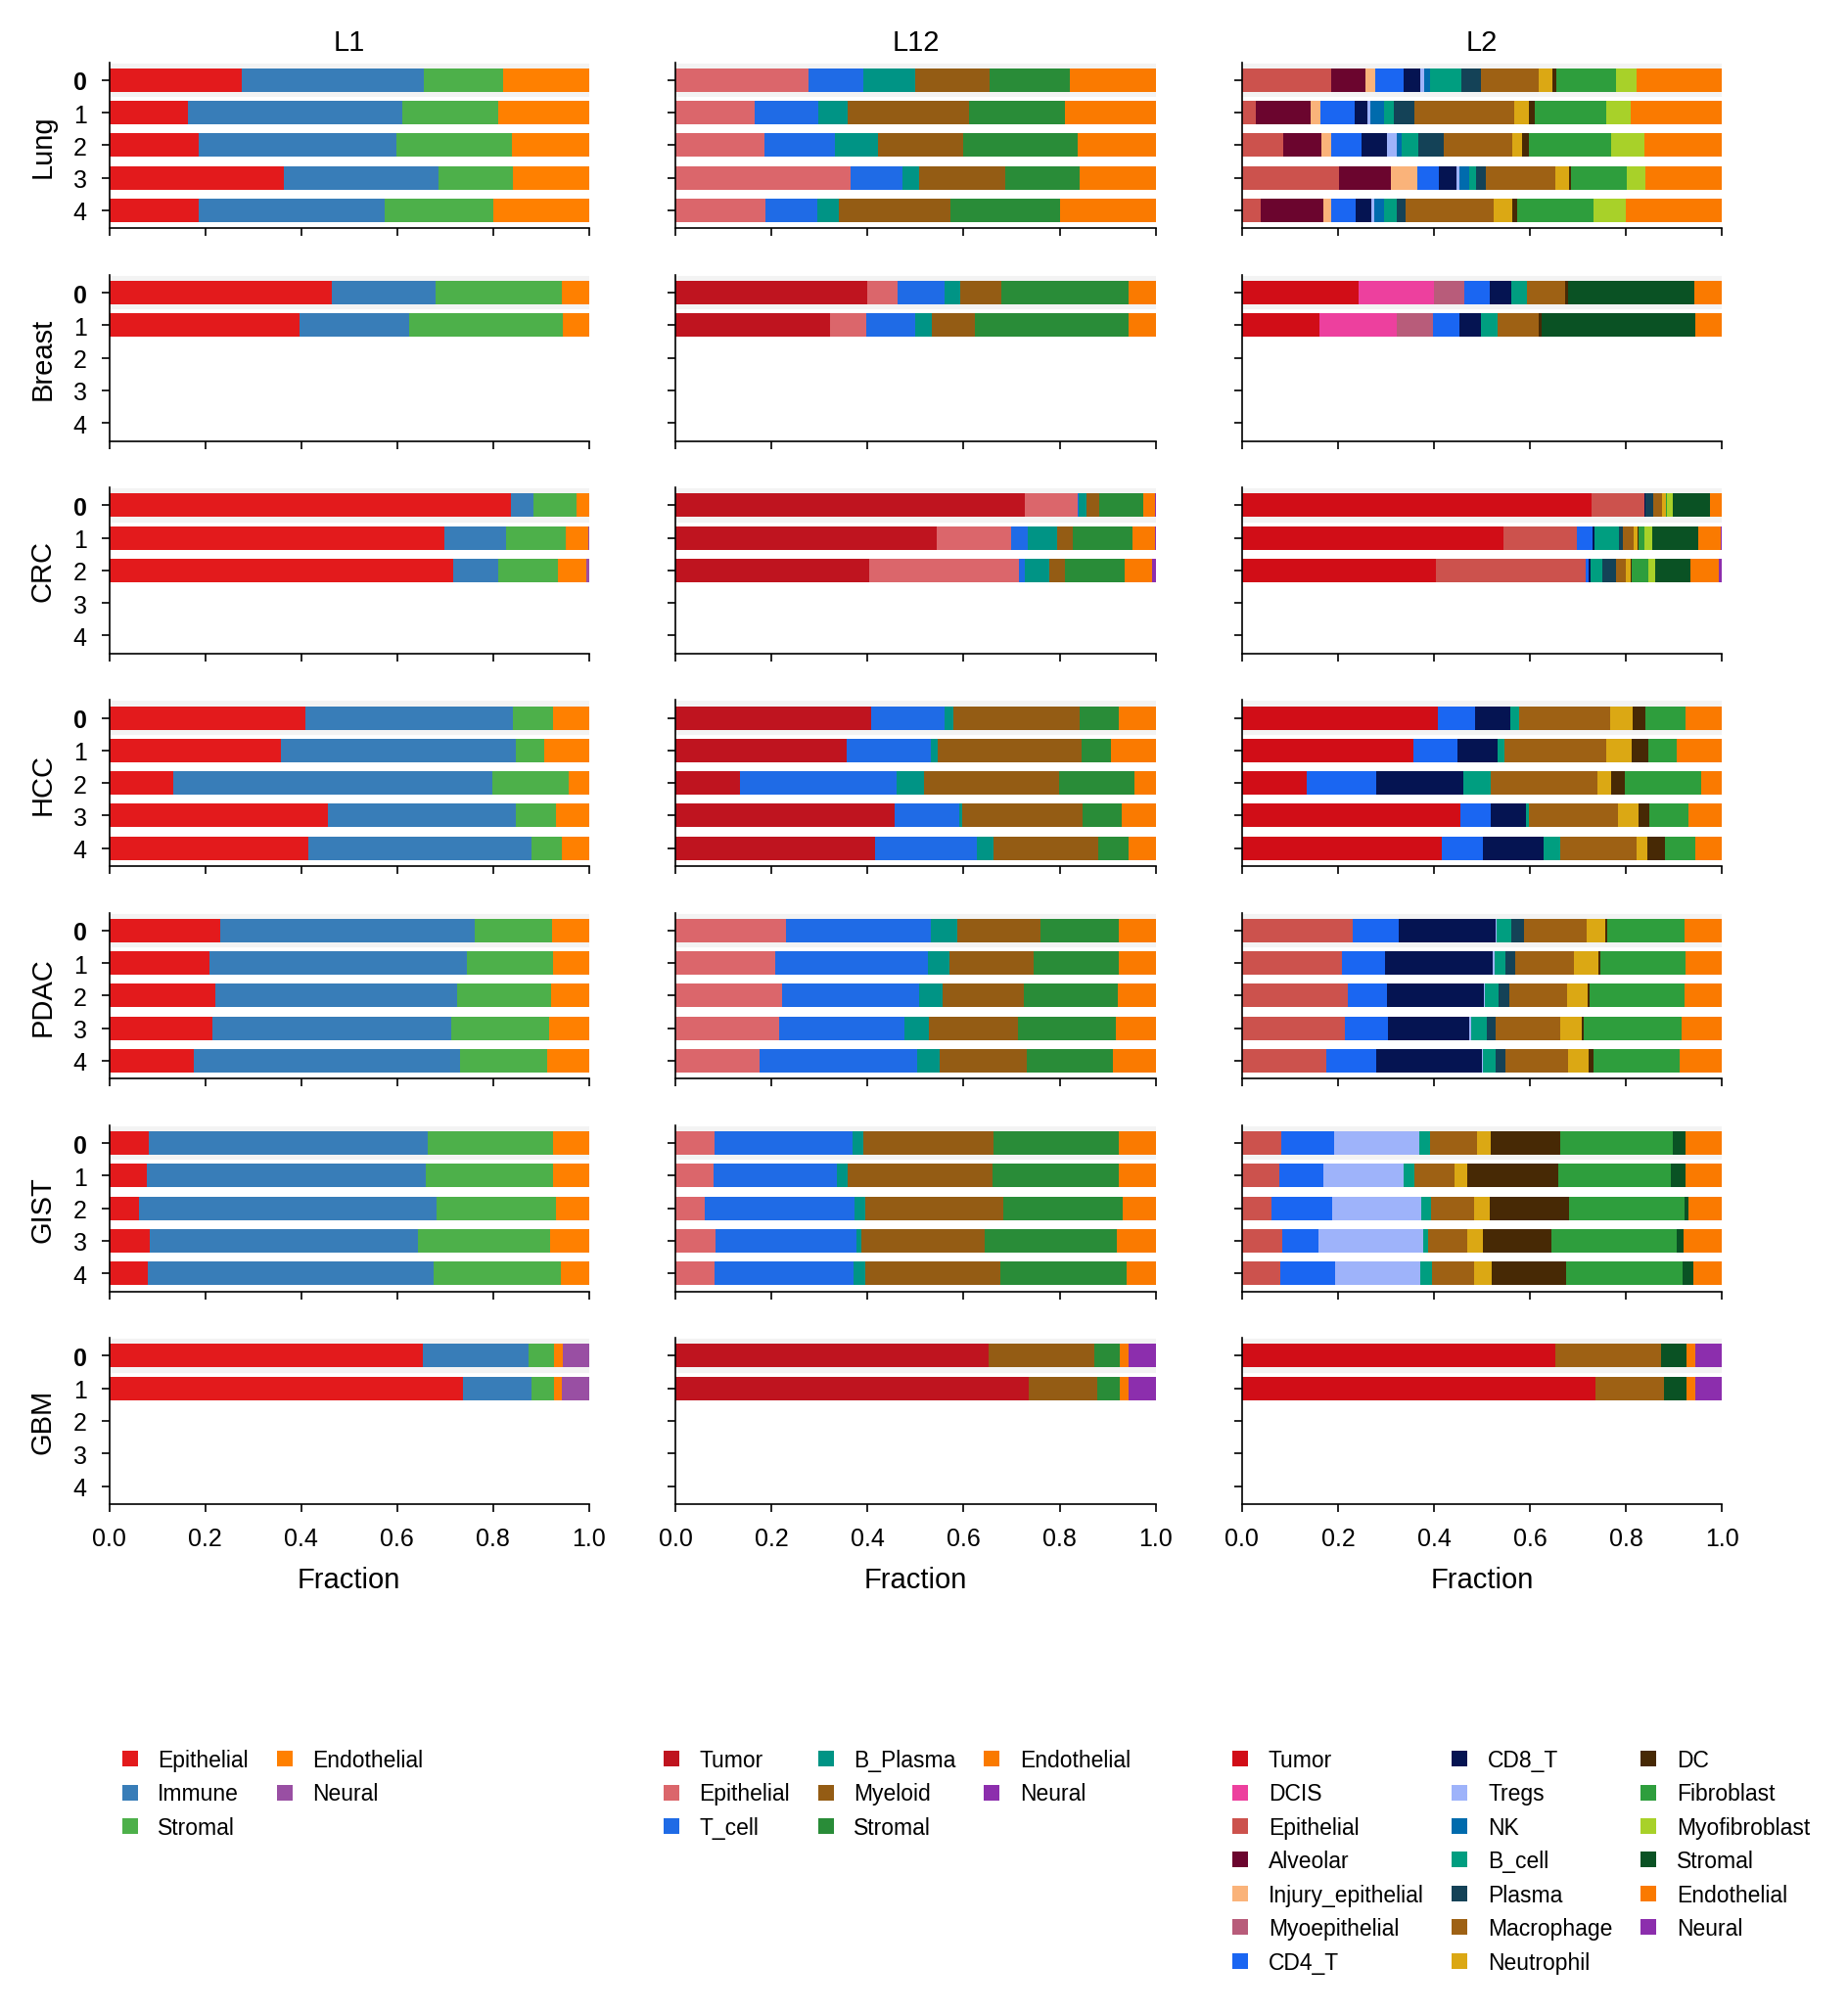

In [4]:

CACHE = DATA / "PanCancer/label_cache"
cell_counts = (
    fold.groupby(["dataset", "fold"])["n_keep"].sum()
    .unstack("fold")
    .reindex(index=ORDER, columns=[0, 1, 2, 3, 4])
    .fillna(0)
    .astype(int)
)
cell_counts.to_csv(OUT / "fig2a_cell_counts.csv")
display(cell_counts.rename(index=SHOW))

fig, ax = plt.subplots(figsize=(14.2 / 2.54, 7.4 / 2.54))
ax.set_xlim(-1.7, 4.65)
ax.set_ylim(len(ORDER) - 0.45, -1.25)
ax.axis("off")
ax.text(2, -1.05, "Validation fold", ha="center", va="center", fontsize=7)
for j, fold_id in enumerate(range(5)):
    ax.text(j, -0.62, str(fold_id), ha="center", va="center", fontsize=7,
            fontweight="bold" if fold_id == 0 else "regular")
for i, dataset in enumerate(ORDER):
    ax.text(-0.62, i, SHOW.get(dataset, dataset), ha="right", va="center", fontsize=7)
    for j, fold_id in enumerate(range(5)):
        value = int(cell_counts.loc[dataset, fold_id])
        if value == 0:
            continue
        ax.add_patch(plt.Rectangle(
            (j - 0.46, i - 0.34), 0.92, 0.68,
            facecolor="#E8E8E8" if fold_id == 0 else "white",
            edgecolor="black", linewidth=0.5, zorder=2,
        ))
        ax.text(j, i, f"{value:,}", ha="center", va="center", fontsize=6, zorder=3)
save_fig(fig, "fig2a_cell_counts")

LEVEL_ARRAY = {"L1": "y_l1", "L12": "y_l12", "L2": "y"}
PALETTE = {"L1": L1_PALETTE, "L12": L12_PALETTE, "L2": L2_PALETTE}
from collections import Counter
gt_counts = {}
for rec in fold.itertuples(index=False):
    cache_path = CACHE / f"{rec.section_id.replace('::', '__')}.npz"
    z = np.load(cache_path, allow_pickle=True)
    for level, key in LEVEL_ARRAY.items():
        labels, n = np.unique(z[key], return_counts=True)
        bucket = gt_counts.setdefault((rec.dataset, int(rec.fold), level), Counter())
        for label, count in zip(labels, n):
            bucket[str(label)] += int(count)

rows = []
for (dataset, fold_id, level), bucket in gt_counts.items():
    total = sum(bucket.values())
    for label, count in bucket.items():
        rows.append({
            "dataset": dataset,
            "fold": fold_id,
            "level": level,
            "label": label,
            "n": count,
            "fraction": count / total,
        })
gt_table = pd.DataFrame(rows).sort_values(["level", "dataset", "fold", "label"])
gt_table.to_csv(OUT / "fig2a_gt_composition.csv", index=False)
print(f"kept cells in cache {int(gt_table.loc[gt_table.level == 'L2', 'n'].sum()):,}")

fig, axes = plt.subplots(
    len(ORDER), 3,
    figsize=(18.0 / 2.54, 16.2 / 2.54),
    sharex=True,
    gridspec_kw={"wspace": 0.18, "hspace": 0.28},
)
for i, dataset in enumerate(ORDER):
    for j, level in enumerate(("L1", "L12", "L2")):
        ax = axes[i, j]
        ax.axhspan(-0.46, 0.46, color="#F3F3F3", zorder=0)
        palette = PALETTE[level]
        present = [
            name for name in palette
            if any(gt_counts.get((dataset, fold_id, level), {}).get(name, 0) for fold_id in range(5))
        ]
        for fold_id in range(5):
            bucket = gt_counts.get((dataset, fold_id, level), {})
            total = sum(bucket.values())
            if total == 0:
                continue
            left = 0.0
            for name in present:
                count = bucket.get(name, 0)
                if count == 0:
                    continue
                width = count / total
                ax.barh(
                    fold_id, width, left=left, height=0.72,
                    color=palette[name], linewidth=0, zorder=2,
                )
                left += width
        ax.set_xlim(0, 1)
        ax.set_ylim(4.55, -0.55)
        ax.tick_params(length=2, width=0.4)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        if j == 0:
            ax.set_yticks(range(5))
            ax.set_yticklabels([str(k) for k in range(5)])
            for tick in ax.get_yticklabels():
                if tick.get_text() == "0":
                    tick.set_fontweight("bold")
            ax.set_ylabel(SHOW.get(dataset, dataset), fontsize=7)
        else:
            ax.set_yticks(range(5))
            ax.set_yticklabels([])
        if i == 0:
            ax.set_title(level, fontsize=7, pad=3)
        if i == len(ORDER) - 1:
            ax.set_xlabel("Fraction", fontsize=7)
        else:
            ax.set_xlabel("")
            ax.tick_params(labelbottom=False)

for j, level in enumerate(("L1", "L12", "L2")):
    palette = PALETTE[level]
    used = {
        row.label
        for row in gt_table.itertuples(index=False)
        if row.level == level
    }
    present = [name for name in palette if name in used]
    handles = [
        plt.Line2D(
            [0], [0], linestyle="none", marker="s", markersize=4,
            markerfacecolor=palette[name], markeredgecolor="none", label=name,
        )
        for name in present
    ]
    fig.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.20 + 0.30 * j, -0.01),
        frameon=False,
        fontsize=5.5,
        ncol=2 if level == "L1" else 3,
        columnspacing=0.6,
        handletextpad=0.25,
    )
fig.savefig(OUT / "fig2a_gt_composition.png", dpi=300, bbox_inches="tight", facecolor="white")
fig.savefig(OUT / "fig2a_gt_composition.pdf", bbox_inches="tight", facecolor="white")
plt.close(fig)
print(OUT / "fig2a_gt_composition.png")
if Image is not None:
    display(Image(filename=str(OUT / "fig2a_gt_composition.png")))


## Figure 2b. Held-out macro-AUROC

每个点是 fold 0 的一张切片。`fold0_scores` 把 `metrics_per_section.csv` 接到 `fold_plan.csv`，只保留 `fold == 0`。CRC 在这一折留出的是 P2CRC。P5CRC 在 fold 2，划分图里有它，这张分数图不画。LungIncomplete 没有病理标注，也不画。黑竖线是四分位距，黑横线是中位数。

  Lung: n=5 median L1/L12/L2 0.766 0.777 0.728
  Breast: n=1 median L1/L12/L2 0.858 0.810 0.772
  CRC: n=1 median L1/L12/L2 0.638 0.605 0.611
  HCC: n=8 median L1/L12/L2 0.769 0.770 0.741
  PDAC: n=56 median L1/L12/L2 0.765 0.766 0.713
  GIST: n=110 median L1/L12/L2 0.655 0.635 0.643
  GBM: n=1 median L1/L12/L2 0.541 0.546 0.533


level,L1,L12,L2
cancer,,,
Lung,0.765607,0.777155,0.728351
Breast,0.857683,0.810280,0.771827
CRC,0.638152,0.604510,0.610953
HCC,0.769457,0.770460,0.740528
PDAC,0.765040,0.765579,0.713242
GIST,0.655361,0.634713,0.642847
GBM,0.540660,0.545694,0.533033


/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2b_fold0_macro_auroc.png


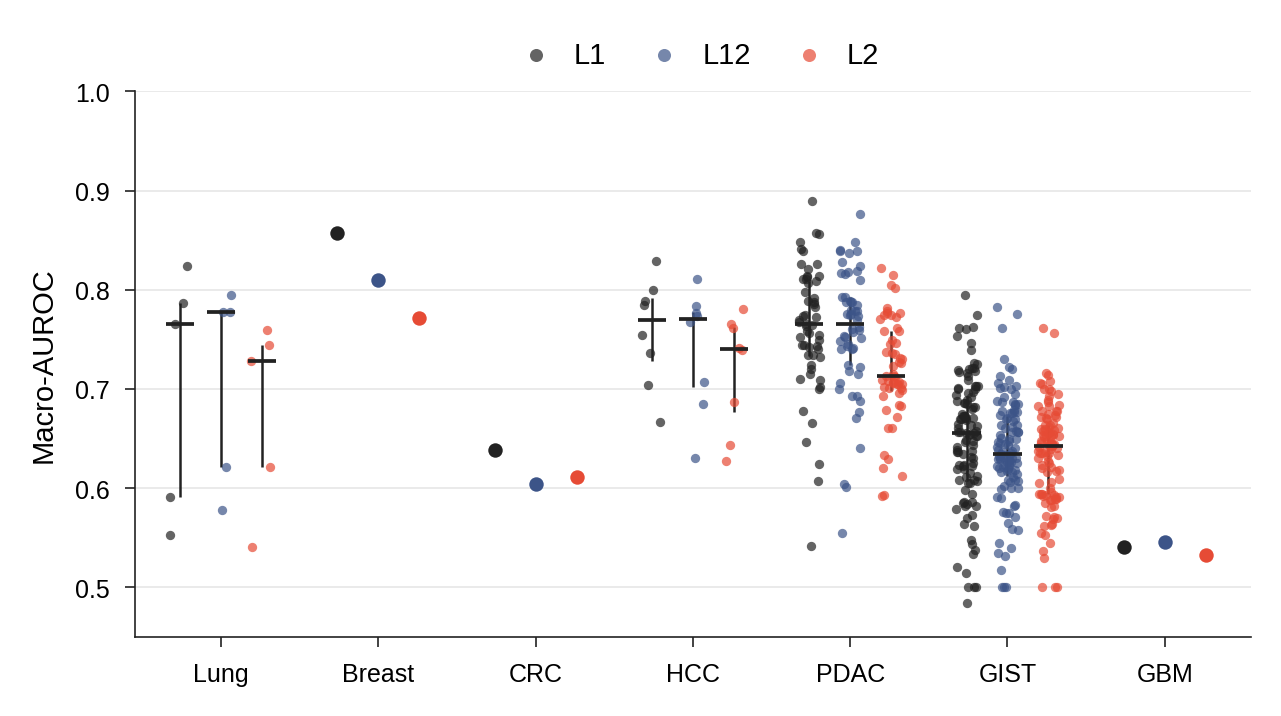

PosixPath('/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2b_fold0_macro_auroc.png')

In [5]:
series = fig23.fold0_scores()
rows = []
for name, levels in series:
    n = len(levels["L2"])
    for level, values in levels.items():
        for value in values:
            rows.append({"cancer": name, "level": level, "macro_auroc": value, "n_sections": n})
points = pd.DataFrame(rows)
points.to_csv(OUT / "fig2b_fold0_macro_auroc.csv", index=False)
summary = (
    points.groupby(["cancer", "level"])["macro_auroc"]
    .agg(n="size", median="median")
    .reset_index()
)
display(summary.pivot(index="cancer", columns="level", values="median").reindex(
    [name for name, _ in series]
)[["L1", "L12", "L2"]])

fig, ax = plt.subplots(figsize=(12.2 / 2.54, 6.0 / 2.54))
rng = np.random.default_rng(0)
levels = ("L1", "L12", "L2")
for i, (name, grouped) in enumerate(series):
    for j, level in enumerate(levels):
        vals = np.asarray(grouped[level], dtype=float)
        xx = i + (j - 1) * 0.26
        color = fig23.LEVEL_COLOR[level]
        if len(vals) > 1:
            q1, med, q3 = np.percentile(vals, [25, 50, 75])
            ax.plot([xx, xx], [q1, q3], color="#222222", lw=0.6, zorder=2, solid_capstyle="butt")
            jitter = rng.uniform(-0.07, 0.07, size=len(vals))
            ax.scatter(
                np.full(len(vals), xx) + jitter, vals,
                s=5, c=color, alpha=0.7, linewidths=0, zorder=3,
                label=level if i == 0 else None,
            )
            ax.plot([xx - 0.09, xx + 0.09], [med, med], color="#222222", lw=0.9, zorder=4, solid_capstyle="butt")
        else:
            ax.scatter([xx], vals, s=12, c=color, linewidths=0, zorder=3, label=level if i == 0 else None)
ax.set_xticks(range(len(series)))
ax.set_xticklabels([name for name, _ in series])
ax.set_ylabel("Macro-AUROC")
ax.set_xlim(-0.55, len(series) - 0.45)
ax.set_ylim(0.45, 1.0)
ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
ax.yaxis.grid(True, color="#E6E6E6", lw=0.4, zorder=0)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
for spine in ax.spines.values():
    spine.set_color("#222222")
    spine.set_linewidth(0.4)
ax.tick_params(length=2.5, width=0.4, color="#222222")
ax.legend(
    frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.02),
    borderaxespad=0, handletextpad=0.3, columnspacing=1.0, markerscale=1.4,
)
save_fig(fig, "fig2b_fold0_macro_auroc")


## Figure 2c. Held-out HCC section

`kqr-83230_aligned_3bba12d6` 在 fold 0。接触表 PNG 早于现在的 `plotting_palettes.py`，所以这里不裁那张图，而是用 `matched_pred.h5ad` 重画。颜色是 `get_palette("pancancer")`：L1 coarse、L12 intermediate、L2 fine。每一列最下方是该列在标注或预测里出现过的类。

L1 ['Epithelial', 'Immune', 'Stromal', 'Endothelial']
L12 ['Tumor', 'T_cell', 'B_Plasma', 'Myeloid', 'Stromal', 'Endothelial']
L2 ['Tumor', 'CD4_T', 'CD8_T', 'B_cell', 'Macrophage', 'Neutrophil', 'DC', 'Fibroblast', 'Stromal', 'Endothelial']
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2c_hcc_gt_pred.png


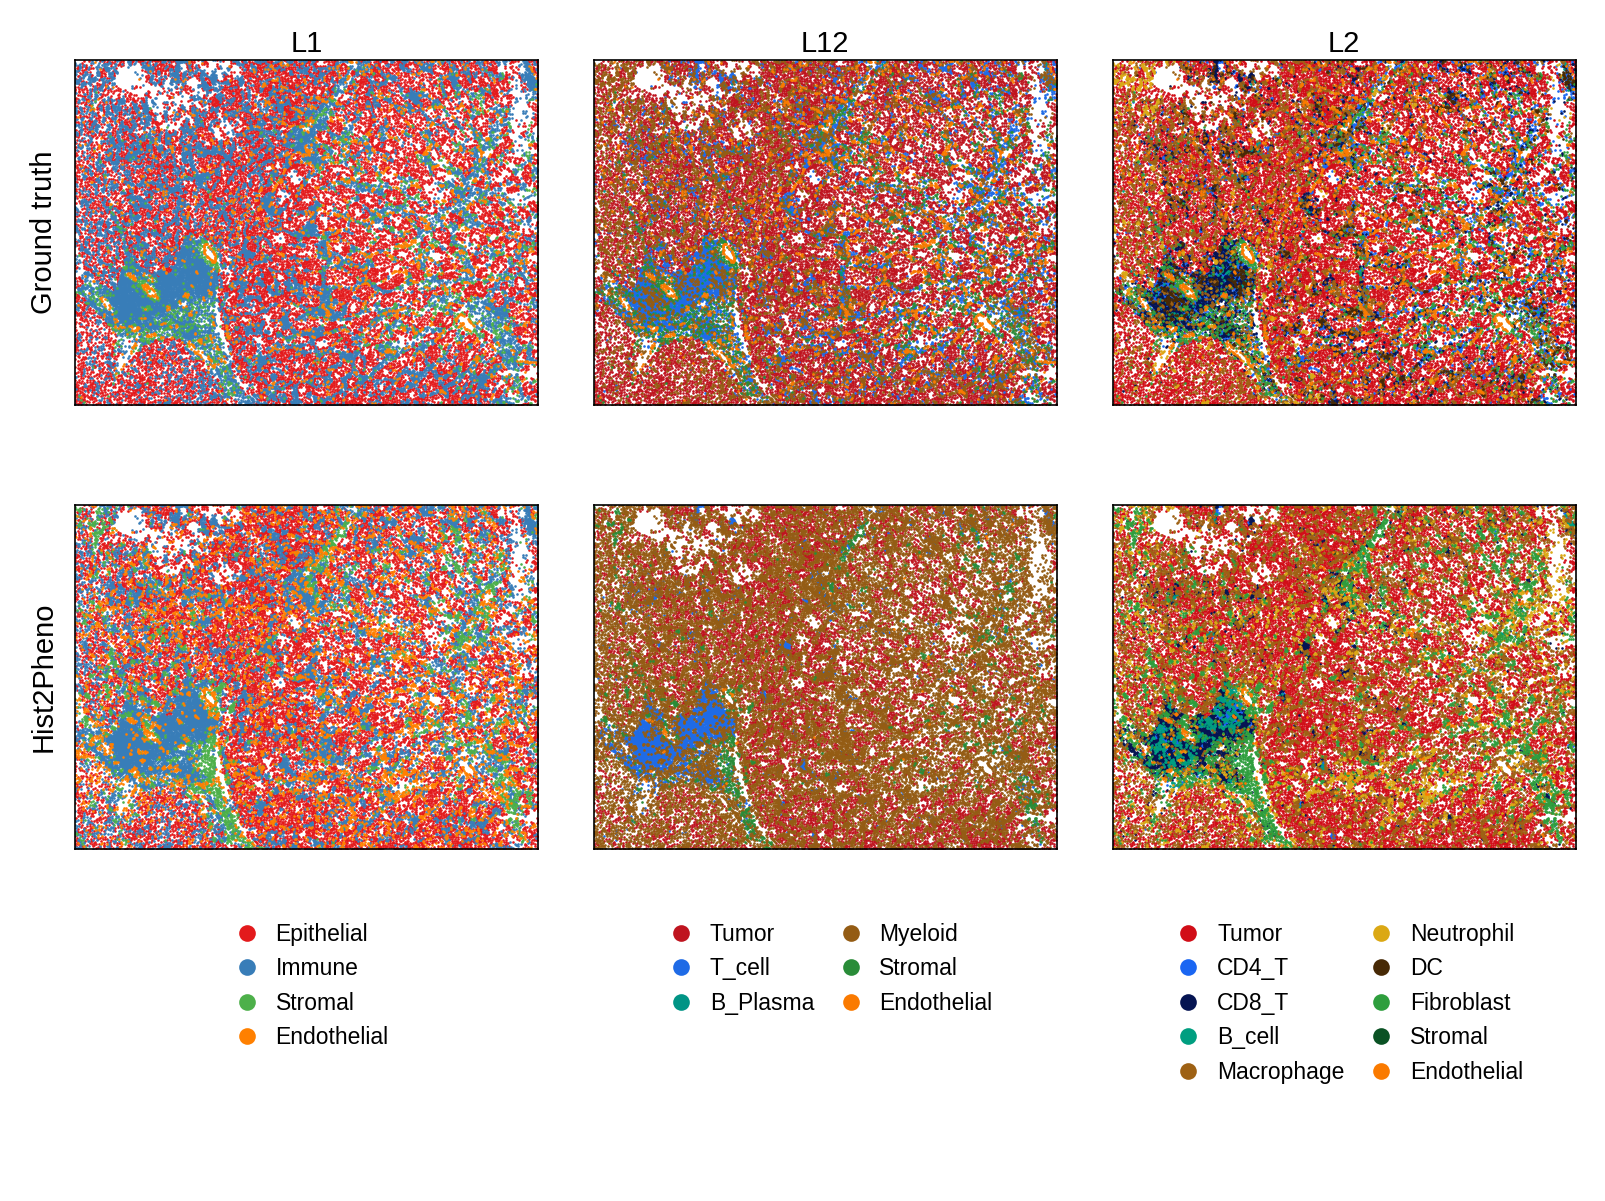

PosixPath('/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2c_hcc_gt_pred.png')

In [6]:
import anndata as ad
from matplotlib.lines import Line2D

hcc_h5 = (
    DATA / "PanCancer/pred_all_spatial/matched/HCC/kqr-83230_aligned_3bba12d6"
    / "kqr-83230_aligned_3bba12d6_matched_pred.h5ad"
)
adata = ad.read_h5ad(hcc_h5)
xy = np.asarray(adata.obsm["spatial_HE"], dtype=np.float64)
columns = [
    ("L1", "final_lineage", "pred_lineage", L1_PALETTE),
    ("L12", "final_sublineage", "pred_sublineage", L12_PALETTE),
    ("L2", "final_CT", "pred_CT", L2_PALETTE),
]

def scatter_labels(ax, labels, palette):
    labels = np.asarray(labels, dtype=str)
    for name, color in palette.items():
        mask = labels == name
        if np.any(mask):
            ax.scatter(
                xy[mask, 0], xy[mask, 1], s=0.4, c=[color],
                linewidths=0, rasterized=True,
            )
    ax.set_xlim(xy[:, 0].min(), xy[:, 0].max())
    ax.set_ylim(xy[:, 1].max(), xy[:, 1].min())
    ax.set_aspect("equal", adjustable="box")
    ax.set_xticks([])
    ax.set_yticks([])

fig = plt.figure(figsize=(16.4 / 2.54, 12.6 / 2.54))
gs = fig.add_gridspec(3, 3, height_ratios=[1.0, 1.0, 0.62], hspace=0.08, wspace=0.12)
for j, (head, gt_col, pred_col, palette) in enumerate(columns):
    for i, (col, row_name) in enumerate(((gt_col, "Ground truth"), (pred_col, "Hist2Pheno"))):
        ax = fig.add_subplot(gs[i, j])
        scatter_labels(ax, adata.obs[col].to_numpy(), palette)
        if i == 0:
            ax.set_title(head, fontsize=7, pad=2)
        if j == 0:
            ax.set_ylabel(row_name, fontsize=7)
    seen = set(adata.obs[gt_col].astype(str)) | set(adata.obs[pred_col].astype(str))
    present = [name for name in palette if name in seen]
    axL = fig.add_subplot(gs[2, j])
    axL.axis("off")
    handles = [
        Line2D(
            [0], [0], linestyle="none", marker="o", markersize=4,
            markerfacecolor=palette[name], markeredgecolor="none", label=name,
        )
        for name in present
    ]
    axL.legend(
        handles=handles, loc="upper center", frameon=False, fontsize=5.5,
        ncol=2 if len(present) > 4 else 1,
        columnspacing=0.6, handletextpad=0.25, borderaxespad=0.0,
    )
    print(head, present)

save_fig(fig, "fig2c_hcc_gt_pred")

## Figure 2d. Class-wise ROC on that section

`stardist_roc/` 里的 CSV 是逐核的预测和概率，不是已经算好的 AUC。这里按 `macro_auc_ovr` 的规则重画 one-versus-rest：某一类在该切片上没有阳性或没有阴性就不画。

L1 macro-AUROC 0.789
L12 macro-AUROC 0.783
L2 macro-AUROC 0.766
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2d_hcc_roc.png


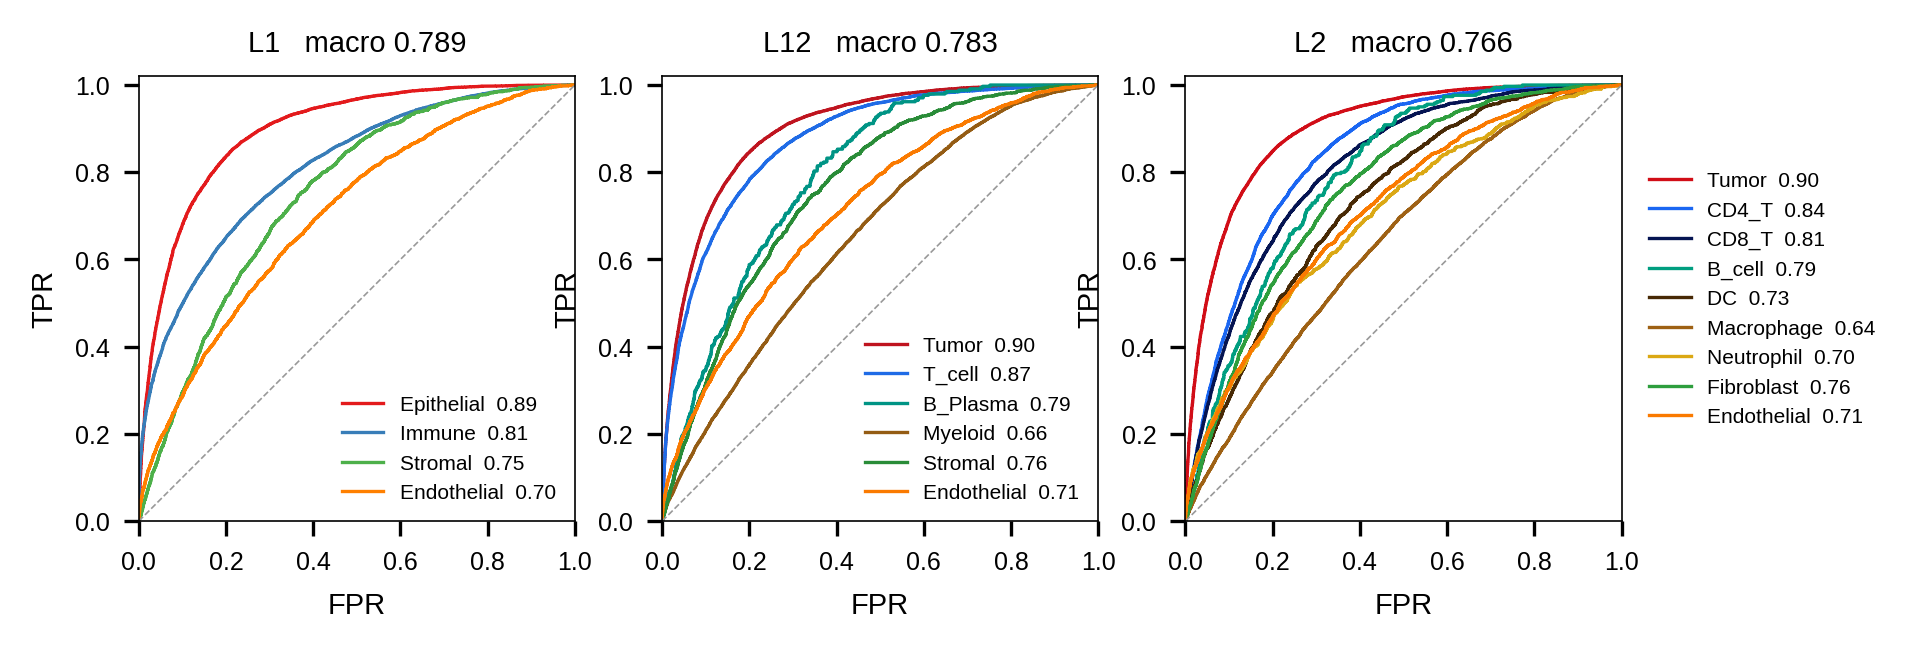

PosixPath('/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig2d_hcc_roc.png')

In [7]:
ROC_DIR = DATA / "PanCancer/pred_all_spatial/stardist_roc/HCC__kqr-83230_aligned_3bba12d6"

def load_tier(pred_name, names_name, name_col):
    pred = pd.read_csv(ROC_DIR / pred_name)
    names = pd.read_csv(ROC_DIR / names_name).sort_values("class_index")
    classes = names[name_col].astype(str).tolist()
    prob_cols = sorted(
        [c for c in pred.columns if c.startswith("prob_")],
        key=lambda c: int(c.split("_")[1]),
    )
    y = pred["ground_truth_idx"].to_numpy(dtype=np.int64)
    score = pred[prob_cols].to_numpy(dtype=np.float64)
    if score.shape[1] != len(classes):
        raise RuntimeError(f"{pred_name}: {score.shape[1]} probability columns, {len(classes)} classes")
    return classes, y, score

from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

tiers = {
    "L1": load_tier(
        "validation_external_stardist_matched_AUROC_level1.csv",
        "validation_external_stardist_matched_AUROC_level1_class_names.csv",
        "final_lineage",
    ),
    "L12": load_tier(
        "validation_external_stardist_matched_AUROC_level12.csv",
        "validation_external_stardist_matched_AUROC_level12_class_names.csv",
        "final_sublineage",
    ),
    "L2": load_tier(
        "validation_external_stardist_matched_AUROC.csv",
        "validation_external_stardist_matched_AUROC_class_names.csv",
        "final_CT",
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(16.2 / 2.54, 5.6 / 2.54))
auc_rows = []
for ax, level in zip(axes, ("L1", "L12", "L2")):
    classes, y, score = tiers[level]
    macro = macro_auc_ovr(y, score, len(classes))
    Y = label_binarize(y, classes=np.arange(len(classes)))
    if Y.ndim == 1:
        Y = np.column_stack([1 - Y, Y])
    palette = TIER_PALETTE[level]
    for k, name in enumerate(classes):
        pos = int(Y[:, k].sum())
        if pos == 0 or pos == len(Y):
            continue
        fpr, tpr, _ = roc_curve(Y[:, k], score[:, k])
        class_auc = float(auc(fpr, tpr))
        ax.plot(fpr, tpr, color=palette.get(name, (0.4, 0.4, 0.4, 1)), lw=0.8, label=f"{name}  {class_auc:.2f}")
        auc_rows.append({"level": level, "class": name, "auroc": class_auc, "n_positive": pos})
    ax.plot([0, 1], [0, 1], color="0.6", lw=0.4, ls="--")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("FPR")
    ax.set_ylabel("TPR")
    ax.set_title(f"{level}   macro {macro:.3f}")
    ax.set_aspect("equal", adjustable="box")
    if level == "L2":
        ax.legend(frameon=False, fontsize=5, loc="center left", bbox_to_anchor=(1.02, 0.5))
    else:
        ax.legend(frameon=False, fontsize=5, loc="lower right")
    print(f"{level} macro-AUROC {macro:.3f}")

pd.DataFrame(auc_rows).to_csv(OUT / "fig2d_hcc_per_class_auroc.csv", index=False)
save_fig(fig, "fig2d_hcc_roc")

## Figure 3. Fields already on disk

每一行四格的顺序是 H&E、细胞核 L2、spot、一个 niche。这一格只导出已经画好的 H&E、L2 和 niche。

- L2 取空间图的右栏。
- Niche 取三栏图的中间栏，也就是半径 55 µm 的空间得分。
- HCC 用 `P1_N` 和 `P1_T` 的 SRI。
- GBM 用 `P174511_Initial` 接触表最下面一行的 L2，也就是全部 StarDist 核。
- CRC 的 H&E 是 11 GB BigTIFF，这里不解码。

In [8]:
def export_he(src, dest):
    if src is None or not Path(src).is_file():
        print("H&E left blank:", dest.name)
        return None
    fig23.he_thumb(src, dest, max_px=900)
    print(dest)
    return dest

fields = []

def add_field(letter, cancer, kind, path):
    fields.append({"letter": letter, "cancer": cancer, "field": kind, "path": str(path) if path else ""})

specs = [
    ("a", "Prostate",
     DATA / "Visium/Prostate/Patient_1/HE_images/H1_2.jpg",
     DATA / "Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_2_spatial_L1_L12_L2.png",
     DATA / "Visium/Prostate/pred_pancancer_section/figures/Patient_1__H1_2_TLS_abundance_vs_spatial.png",
     "tls"),
    ("b", "NPC",
     DATA / "Visium/NPC/HE_images/20210809-C-AH4199551.tif",
     DATA / "Visium/NPC/pred_pancancer_section/figures/20210809-C-AH4199551_spatial_L1_L12_L2.png",
     DATA / "Visium/NPC/pred_pancancer_section/figures/20210809-C-AH4199551_TLS_abundance_vs_spatial.png",
     "tls"),
    ("c_N", "HCC P1_N",
     DATA / "Visium/HCC/HE_images/P1_N.jpg",
     DATA / "Visium/HCC/pred_pancancer_section/figures/P1_N_spatial_L1_L12_L2.png",
     DATA / "Visium/HCC/pred_pancancer_section/figures/P1_N_SRI_abundance_vs_spatial.png",
     "sri"),
    ("c_T", "HCC P1_T",
     DATA / "Visium/HCC/HE_images/P1_T.jpg",
     DATA / "Visium/HCC/pred_pancancer_section/figures/P1_T_spatial_L1_L12_L2.png",
     DATA / "Visium/HCC/pred_pancancer_section/figures/P1_T_SRI_abundance_vs_spatial.png",
     "sri"),
    ("d", "Breast",
     DATA / "ST/BRCA/HE_images/10426_HE_BT_C1.jpg",
     DATA / "ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C1_spatial_L1_L12_L2.png",
     DATA / "ST/BRCA/pred_pancancer_section/figures/10426_HE_BT_C1_TLS_abundance_vs_spatial.png",
     "tls"),
    ("e", "CRC",
     None,
     DATA / "Visium/CRC/pred_pancancer_section/figures/Visium_V2_Human_Colon_Cancer_P2_tissue_image_spatial_L1_L12_L2.png",
     DATA / "Visium/CRC/pred_pancancer_section/figures/Visium_V2_Human_Colon_Cancer_P2_tissue_image_TLS_abundance_vs_spatial.png",
     "tls"),
]

for letter, cancer, he, spatial, niche, niche_name in specs:
    he_out = OUT / f"fig3{letter}_he.jpg"
    l2_out = OUT / f"fig3{letter}_l2.png"
    niche_out = OUT / f"fig3{letter}_{niche_name}.png"
    export_he(he, he_out)
    fig23.l2_third(spatial, l2_out)
    fig23.niche_middle(niche, niche_out)
    print(l2_out)
    print(niche_out)
    add_field(letter, cancer, "H&E", he_out if he else None)
    add_field(letter, cancer, "L2", l2_out)
    add_field(letter, cancer, niche_name, niche_out)

gbm_he = (
    DATA / "CODEX/GBM/WangLab/4_Images/CytAssist_Image"
    / "P174511_2_3_2024-05-11_14-33-44_2024-05-11_14-05-32_H1-8BZDCBG_A1_sample.tif"
)
gbm_panel = (
    DATA / "PanCancer/pred_all_spatial/matched/GBM/P174511_Initial"
    / "P174511_Initial_panel_4x3.png"
)
export_he(gbm_he, OUT / "fig3f_he.jpg")
fig23.gbm_l2(gbm_panel, OUT / "fig3f_l2.png")
print(OUT / "fig3f_l2.png")
add_field("f", "GBM", "H&E", OUT / "fig3f_he.jpg")
add_field("f", "GBM", "L2", OUT / "fig3f_l2.png")
print("CRC H&E source is Visium_V2_Human_Colon_Cancer_P2_tissue_image.btf (11 GB). Drop a JPEG into this folder when it is ready.")

/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3a_he.jpg
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3a_l2.png
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3a_tls.png
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3b_he.jpg
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3b_l2.png
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3b_tls.png
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3c_N_he.jpg
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3c_N_l2.png
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3c_N_sri.png
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3c_T_he.jpg
/home/lingyu/ssd2/Python/Hist2Pheno/cod

## Figure 3 spot composition

细胞核和 spot 画在同一套全分辨率像素上，再按 Li et al., *npj Precision Oncology* (2025) 的 `CTA_align` 把分类收进捕获区。

`CTA_align` 的步骤是：SpaceRanger 的 spot 中心除以 `scaling_factor`，回到显微镜全分辨率；捕获半径是 spot 直径的一半，再除以同一个缩放系数；QuPath 质心若以 µm 存储，除以 µm/px 变成像素；Visium 和 QuPath 的 y 轴相反时，用图像高度做一次翻转。质心落在以 spot 为中心、半边长等于捕获半径的正方形里，才算被这个 spot 捕获；方框外记为 `Not_captured`。每个 spot 内按硬分类计数，再除以该 spot 的核数。

这里的核坐标已经在 H&E 全分辨率上，所以 `scaling_factor = 1`，也不做第二次 y 轴翻转。捕获区用圆盘而不是那个正方形：孔是圆的，半径仍是直径的一半。孔心距大于直径时，一个核至多落入一个圆。颜色是该圆内核数最多的 L2。

- Breast `10426_HE_BT_C1` 对应 HER2ST `D1`。ST 阵列的孔直径是 100 µm，孔心距 200 µm，所以半径是测到的孔心距的 1/4。坐标在 `ST-spotfiles/D1_selection.tsv` 的 `pixel_x`、`pixel_y`，与 `spatial_HE` 同一像素系。
- GBM `P174511_Initial` 用 16 µm bin。bin 铺满组织，用边长等于 bin 的正方形，和 `CTA_align` 的方框同一写法。这张切片没有 softmax，颜色是 bin 内的多数类。
- NPC patient 1 是 `20210809-C-AH4199551`。spot 坐标在 `data/Visium/NPC/patient1/tissue_positions_list.csv`，只用 `in_tissue == 1`。`pxl_col_in_fullres`、`pxl_row_in_fullres` 与 `spatial_HE` 同一像素系，不翻转 y 轴。捕获半径是 `scalefactors_json.json` 里 `spot_diameter_fullres` 的一半。左边是单核 L2，右边是这些 Visium spot 的多数类。
- NPC patient 2 是 `20210809-D-AJ3037946`，坐标在 `data/Visium/NPC/patient2/`，画法与 patient 1 相同。
- Prostate、HCC、CRC 没有可用的 spot 坐标，不画。

In [9]:
import json
import anndata as ad
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Circle
from scipy.spatial import cKDTree

L2_NAMES = list(L2_PALETTE)


def legend_handles(names):
    return [
        Line2D(
            [0], [0], marker="o", color="none", markerfacecolor=L2_PALETTE[name],
            markeredgecolor="none", markersize=4, label=name,
        )
        for name in names
    ]


def draw_spots(xy, dominant, pitch_px, title, stem, counts, marker_radius=None, width_cm=7.4, height_cm=7.2, marker_s=2):
    keep = counts > 0
    xy = np.asarray(xy)[keep]
    dominant = np.asarray(dominant)[keep]
    fig, ax = plt.subplots(figsize=(width_cm / 2.54, height_cm / 2.54))
    present = [name for name in L2_PALETTE if np.any(dominant == name)]
    radius = 0.45 * float(pitch_px) if marker_radius is None else float(marker_radius)
    if len(xy) > 4000:
        for name in present:
            mask = dominant == name
            ax.scatter(xy[mask, 0], xy[mask, 1], s=marker_s, c=[L2_PALETTE[name]], linewidths=0, rasterized=True)
    else:
        patches, colors = [], []
        for name in present:
            for x, y in xy[dominant == name]:
                patches.append(Circle((x, y), radius))
                colors.append(L2_PALETTE[name])
        ax.add_collection(PatchCollection(patches, facecolors=colors, edgecolors="none"))
    pad = float(pitch_px)
    ax.set_xlim(xy[:, 0].min() - pad, xy[:, 0].max() + pad)
    ax.set_ylim(xy[:, 1].max() + pad, xy[:, 1].min() - pad)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    ax.legend(handles=legend_handles(present), frameon=False, fontsize=5, loc="center left", bbox_to_anchor=(1.02, 0.5))
    save_fig(fig, stem)


Breast spots 309, pitch 270.4 px, radius 67.6 px, nuclei assigned 9706 / 57441, spots with nuclei 309
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3d_breast_spot_l2.png


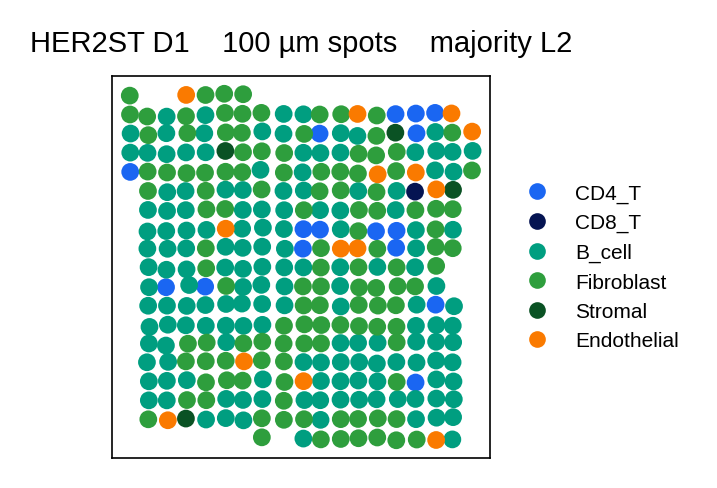

In [15]:
sample = "10426_HE_BT_C1"
pred_path = DATA / "ST/BRCA/pred_pancancer_section" / sample / f"{sample}_stardist_pred.h5ad"
stored = np.load(pred_path.with_name(f"{sample}_l2_probs.npz"), allow_pickle=True)
adata = ad.read_h5ad(pred_path)
nuc_xy = np.asarray(adata.obsm["spatial_HE"], dtype=np.float64)
probs = np.asarray(stored["probs"], dtype=np.float32)
class_names = [str(x) for x in stored["class_names"].tolist()]
if set(class_names) != set(L2_NAMES):
    raise RuntimeError("L2 names in the npz are not the pan-cancer palette")
if probs.shape[0] != nuc_xy.shape[0]:
    raise RuntimeError(f"probs {probs.shape[0]} != nuclei {nuc_xy.shape[0]}")
spots = pd.read_csv(DATA / "ST/BRCA/her2st/data/ST-spotfiles/D1_selection.tsv", sep="\t")
spots = spots.loc[spots["selected"] == 1].reset_index(drop=True)
spot_xy = spots[["pixel_x", "pixel_y"]].to_numpy(dtype=np.float64)
pitch_px = float(np.median(cKDTree(spot_xy).query(spot_xy, k=2)[0][:, 1]))
radius_px = 0.25 * pitch_px
hard = np.array(class_names)[probs.argmax(1)]
captured = nuclei_to_spots(
    nuc_xy, spot_xy, radius_px, shape="circle",
    labels=hard, class_names=class_names, values=probs,
)
counts = captured["n_nuclei"]
breast = spots.copy()
breast["n_nuclei"] = counts
breast["dominant_l2"] = captured["dominant"]
breast["dominant_mean_prob"] = np.where(counts > 0, captured["mean"].max(1), np.nan)
for i, name in enumerate(class_names):
    breast[f"mean_{name}"] = captured["mean"][:, i]
breast.to_csv(OUT / "fig3d_breast_spot_composition.csv", index=False)
print(
    f"Breast spots {len(spot_xy)}, pitch {pitch_px:.1f} px, radius {radius_px:.1f} px, "
    f"nuclei assigned {int(captured['inside'].sum())} / {len(nuc_xy)}, spots with nuclei {(counts > 0).sum()}"
)
draw_spots(
    spot_xy, captured["dominant"], pitch_px,
    "HER2ST D1    100 µm spots    majority L2",
    "fig3d_breast_spot_l2", counts, marker_radius=2*radius_px,
    width_cm=4.4, height_cm=4.2,
)

/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3d_breast_nuclei.png


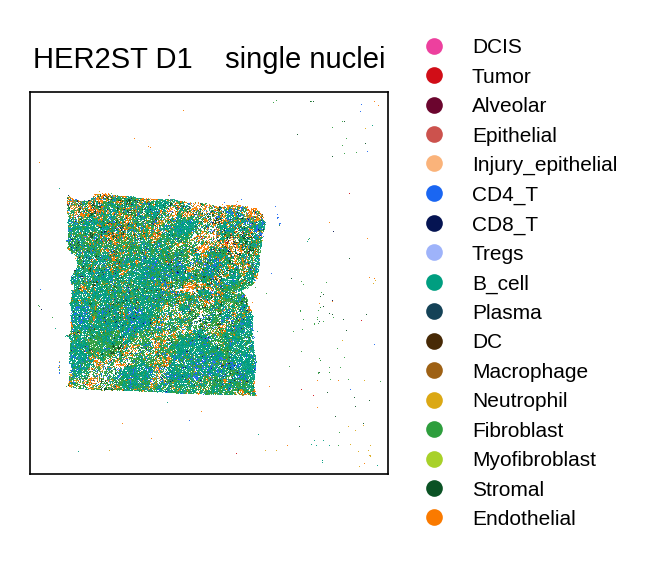

PosixPath('/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3d_breast_nuclei.png')

In [14]:

nucleus_s = 0.05
present = [name for name in class_names if np.any(hard == name)]
fig, ax = plt.subplots(figsize=(4.4 / 2.54, 4.2 / 2.54))
for name in class_names:
    mask = hard == name
    if np.any(mask):
        ax.scatter(
            nuc_xy[mask, 0], nuc_xy[mask, 1], s=nucleus_s,
            c=[L2_PALETTE[name]], linewidths=0, rasterized=True,
        )
pad = pitch_px
ax.set_xlim(nuc_xy[:, 0].min() - pad, nuc_xy[:, 0].max() + pad)
ax.set_ylim(nuc_xy[:, 1].max() + pad, nuc_xy[:, 1].min() - pad)
ax.set_aspect("equal")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("HER2ST D1    single nuclei")
ax.legend(
    handles=legend_handles(present), frameon=False, fontsize=5,
    loc="center left", bbox_to_anchor=(1.02, 0.5),
)
save_fig(fig, "fig3d_breast_nuclei")

GBM bins in tissue 87988, pitch 18.12 px (16.0 µm), nuclei inside a bin 73835 / 178303, bins with nuclei 51983
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3f_gbm_bin16_l2.png


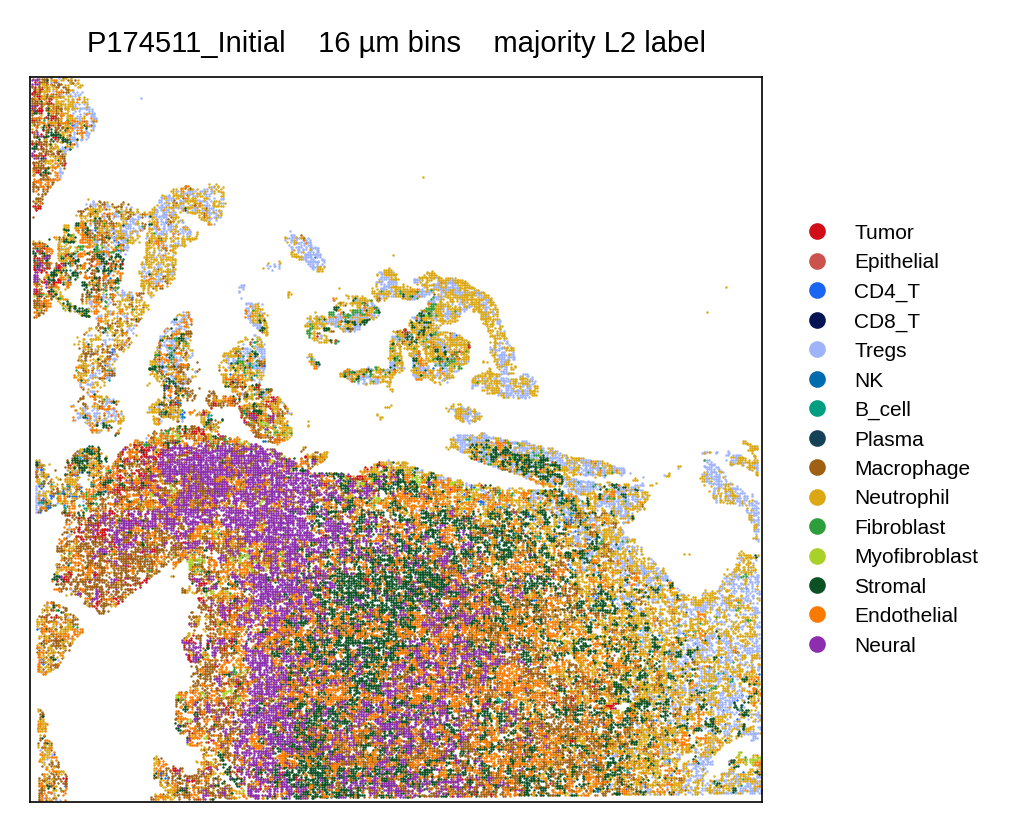

In [11]:

gbm_h5 = (
    DATA / "PanCancer/pred_all_spatial/stardist_all/GBM/P174511_Initial"
    / "P174511_Initial_all_stardist_pred.h5ad"
)
pos_path = DATA / "CODEX/GBM/WangLab/1_Bin_Matrix/P174511_Initial/square_016um/spatial/tissue_positions.parquet"
scale = json.loads(pos_path.with_name("scalefactors_json.json").read_text())
bin_px = float(scale["spot_diameter_fullres"])
gbm = ad.read_h5ad(gbm_h5)
gbm_xy = np.asarray(gbm.obsm["spatial_HE"], dtype=np.float64)
gbm_lab = gbm.obs["pred_CT"].astype(str).to_numpy()
pos = pd.read_parquet(pos_path)
pos = pos.loc[pos["in_tissue"] == 1].reset_index(drop=True)
bin_xy = pos[["pxl_col_in_fullres", "pxl_row_in_fullres"]].to_numpy(dtype=np.float64)
captured = nuclei_to_spots(
    gbm_xy, bin_xy, 0.5 * bin_px, shape="square",
    labels=gbm_lab, class_names=L2_NAMES,
)
counts = captured["n_nuclei"]
used = counts > 0
fraction = np.divide(
    captured["class_counts"].max(1), counts, out=np.zeros(len(counts)), where=used,
)
out = pd.DataFrame({
    "barcode": pos.loc[used, "barcode"].to_numpy(),
    "pixel_x": bin_xy[used, 0],
    "pixel_y": bin_xy[used, 1],
    "n_nuclei": counts[used],
    "dominant_l2": captured["dominant"][used],
    "dominant_fraction": fraction[used],
})
out.to_csv(OUT / "fig3f_gbm_bin16_composition.csv", index=False)
print(
    f"GBM bins in tissue {len(bin_xy)}, pitch {bin_px:.2f} px ({scale['bin_size_um']} µm), "
    f"nuclei inside a bin {int(captured['inside'].sum())} / {len(gbm_xy)}, bins with nuclei {int(used.sum())}"
)
draw_spots(
    bin_xy, captured["dominant"], bin_px,
    "P174511_Initial    16 µm bins    majority L2 label",
    "fig3f_gbm_bin16_l2", counts,
    width_cm=8.0, height_cm=8.0, marker_s=0.35,
)


,L2,single_nucleus,visium_majority
0,Epithelial,0.129937,0.111946
1,CD4_T,0.004586,0.000751
2,CD8_T,0.073602,0.067618
3,Tregs,0.091860,0.048084
4,B_cell,0.002349,0.002254
5,Macrophage,0.000007,0.000000
6,Neutrophil,0.028744,0.010518
7,DC,0.009361,0.013524
8,Fibroblast,0.609260,0.692712
9,Stromal,0.007504,0.005259


NPC 20210809-C-AH4199551: nuclei 142,184, in-tissue spots 1,331, pitch 214.0 px, capture radius 69.7 px, nuclei in a spot 52,669 / 142,184, spots with nuclei 1,331
/home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3/fig3b_npc_nuclei_vs_visium.png


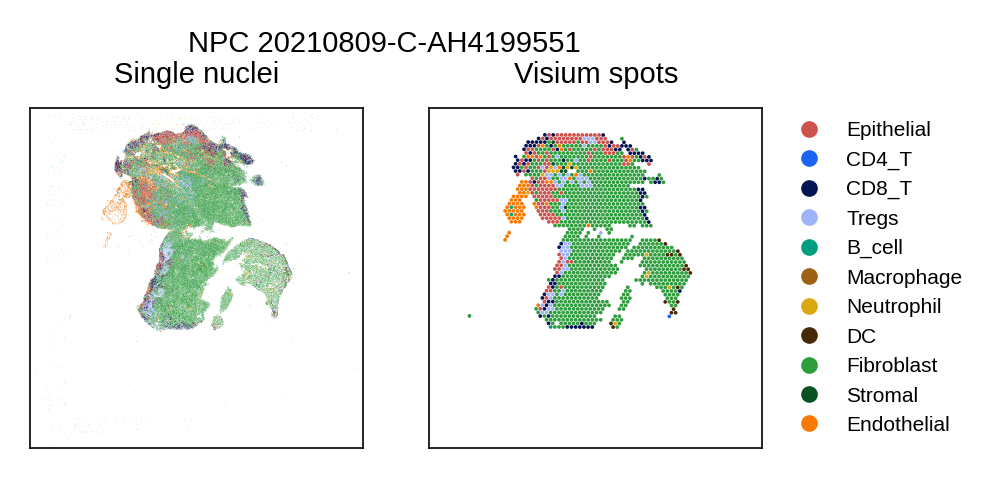

,letter,cancer,reason
0,a,Prostate,No tissue_positions in data/Visium/Prostate
1,c,HCC,No spatial/ directory for the P1_N and P1_T JPEGs
2,e,CRC,No tissue_positions in data/Visium/CRC


In [12]:
sample = "20210809-C-AH4199551"
npc_dir = DATA / "Visium/NPC/patient1"
scale = json.loads((npc_dir / "scalefactors_json.json").read_text())
radius_px = float(scale["spot_diameter_fullres"]) / 2
pos = pd.read_csv(
    npc_dir / "tissue_positions_list.csv",
    header=None,
    names=["barcode", "in_tissue", "array_row", "array_col", "pxl_row", "pxl_col"],
)
pos = pos.loc[pos["in_tissue"] == 1].reset_index(drop=True)
spot_xy = pos[["pxl_col", "pxl_row"]].to_numpy(dtype=np.float64)
pitch_px = float(np.median(cKDTree(spot_xy).query(spot_xy, k=2)[0][:, 1]))
npc = ad.read_h5ad(DATA / "Visium/NPC/pred_pancancer_section" / sample / f"{sample}_stardist_pred.h5ad")
npc_xy = np.asarray(npc.obsm["spatial_HE"], dtype=np.float64)
npc_lab = npc.obs["pred_CT"].astype(str).to_numpy()
captured = nuclei_to_spots(
    npc_xy, spot_xy, radius_px, shape="circle",
    labels=npc_lab, class_names=L2_NAMES,
)
counts = captured["n_nuclei"]
used = counts > 0
npc_spots = pos.loc[used].copy()
npc_spots["pixel_x"] = spot_xy[used, 0]
npc_spots["pixel_y"] = spot_xy[used, 1]
npc_spots["n_nuclei"] = counts[used]
npc_spots["dominant_l2"] = captured["dominant"][used]
for i, name in enumerate(L2_NAMES):
    npc_spots[f"n_{name}"] = captured["class_counts"][used, i]
    npc_spots[f"fraction_{name}"] = captured["class_counts"][used, i] / counts[used]
npc_spots.to_csv(OUT / "fig3b_npc_visium_composition.csv", index=False)
nuc_frac = pd.Series(npc_lab).value_counts(normalize=True)
spot_frac = npc_spots["dominant_l2"].value_counts(normalize=True)
present = [name for name in L2_NAMES if name in set(nuc_frac.index) or name in set(spot_frac.index)]
frac = pd.DataFrame({
    "L2": present,
    "single_nucleus": [float(nuc_frac.get(name, 0.0)) for name in present],
    "visium_majority": [float(spot_frac.get(name, 0.0)) for name in present],
})
frac.to_csv(OUT / "fig3b_npc_class_fraction.csv", index=False)
display(frac)
print(
    f"NPC {sample}: nuclei {len(npc_xy):,}, in-tissue spots {len(spot_xy):,}, "
    f"pitch {pitch_px:.1f} px, capture radius {radius_px:.1f} px, "
    f"nuclei in a spot {int(captured['inside'].sum()):,} / {len(npc_xy):,}, "
    f"spots with nuclei {int(used.sum()):,}"
)

nucleus_s = 0.005
spot_draw_radius = 0.45 * pitch_px

fig, axes = plt.subplots(1, 2, figsize=(8 / 2.54, 4 / 2.54))
axes[0].set_title("Single nuclei")
for name in L2_NAMES:
    mask = npc_lab == name
    if np.any(mask):
        axes[0].scatter(npc_xy[mask, 0], npc_xy[mask, 1], s=nucleus_s,
                        c=[L2_PALETTE[name]], linewidths=0, rasterized=True)
spot_draw = spot_xy[used]
spot_lab = captured["dominant"][used]
patches, colors = [], []
for name in L2_NAMES:
    if not np.any(spot_lab == name):
        continue
    for x, y in spot_draw[spot_lab == name]:
        patches.append(Circle((x, y), spot_draw_radius))
        colors.append(L2_PALETTE[name])
axes[1].add_collection(PatchCollection(patches, facecolors=colors, edgecolors="none"))
axes[1].set_title("Visium spots")
pad = pitch_px
for ax in axes:
    ax.set_xlim(npc_xy[:, 0].min() - pad, npc_xy[:, 0].max() + pad)
    ax.set_ylim(npc_xy[:, 1].max() + pad, npc_xy[:, 1].min() - pad)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(handles=legend_handles(present), frameon=False, fontsize=5, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.suptitle(f"NPC {sample}", fontsize=7, y=1.02)
save_fig(fig, "fig3b_npc_nuclei_vs_visium")

skipped = pd.DataFrame([
    {"letter": "a", "cancer": "Prostate", "reason": "No tissue_positions in data/Visium/Prostate"},
    {"letter": "c", "cancer": "HCC", "reason": "No spatial/ directory for the P1_N and P1_T JPEGs"},
    {"letter": "e", "cancer": "CRC", "reason": "No tissue_positions in data/Visium/CRC"},
])
skipped.to_csv(OUT / "fig3_spot_maps_not_drawn.csv", index=False)
display(skipped)


In [ ]:
sample = "20210809-D-AJ3037946"
npc_dir = DATA / "Visium/NPC/patient2"
scale = json.loads((npc_dir / "scalefactors_json.json").read_text())
radius_px = float(scale["spot_diameter_fullres"]) / 2
pos = pd.read_csv(
    npc_dir / "tissue_positions_list.csv",
    header=None,
    names=["barcode", "in_tissue", "array_row", "array_col", "pxl_row", "pxl_col"],
)
pos = pos.loc[pos["in_tissue"] == 1].reset_index(drop=True)
spot_xy = pos[["pxl_col", "pxl_row"]].to_numpy(dtype=np.float64)
pitch_px = float(np.median(cKDTree(spot_xy).query(spot_xy, k=2)[0][:, 1]))
npc = ad.read_h5ad(DATA / "Visium/NPC/pred_pancancer_section" / sample / f"{sample}_stardist_pred.h5ad")
npc_xy = np.asarray(npc.obsm["spatial_HE"], dtype=np.float64)
npc_lab = npc.obs["pred_CT"].astype(str).to_numpy()
captured = nuclei_to_spots(
    npc_xy, spot_xy, radius_px, shape="circle",
    labels=npc_lab, class_names=L2_NAMES,
)
counts = captured["n_nuclei"]
used = counts > 0
npc_spots = pos.loc[used].copy()
npc_spots["pixel_x"] = spot_xy[used, 0]
npc_spots["pixel_y"] = spot_xy[used, 1]
npc_spots["n_nuclei"] = counts[used]
npc_spots["dominant_l2"] = captured["dominant"][used]
for i, name in enumerate(L2_NAMES):
    npc_spots[f"n_{name}"] = captured["class_counts"][used, i]
    npc_spots[f"fraction_{name}"] = captured["class_counts"][used, i] / counts[used]
npc_spots.to_csv(OUT / "fig3b_npc_p2_visium_composition.csv", index=False)
nuc_frac = pd.Series(npc_lab).value_counts(normalize=True)
spot_frac = npc_spots["dominant_l2"].value_counts(normalize=True)
present = [name for name in L2_NAMES if name in set(nuc_frac.index) or name in set(spot_frac.index)]
frac = pd.DataFrame({
    "L2": present,
    "single_nucleus": [float(nuc_frac.get(name, 0.0)) for name in present],
    "visium_majority": [float(spot_frac.get(name, 0.0)) for name in present],
})
frac.to_csv(OUT / "fig3b_npc_p2_class_fraction.csv", index=False)
display(frac)
print(
    f"NPC {sample}: nuclei {len(npc_xy):,}, in-tissue spots {len(spot_xy):,}, "
    f"pitch {pitch_px:.1f} px, capture radius {radius_px:.1f} px, "
    f"nuclei in a spot {int(captured['inside'].sum()):,} / {len(npc_xy):,}, "
    f"spots with nuclei {int(used.sum()):,}"
)

nucleus_s = 0.005
spot_draw_radius = 0.45 * pitch_px

fig, axes = plt.subplots(1, 2, figsize=(8 / 2.54, 4 / 2.54))
axes[0].set_title("Single nuclei")
for name in L2_NAMES:
    mask = npc_lab == name
    if np.any(mask):
        axes[0].scatter(npc_xy[mask, 0], npc_xy[mask, 1], s=nucleus_s,
                        c=[L2_PALETTE[name]], linewidths=0, rasterized=True)
spot_draw = spot_xy[used]
spot_lab = captured["dominant"][used]
patches, colors = [], []
for name in L2_NAMES:
    if not np.any(spot_lab == name):
        continue
    for x, y in spot_draw[spot_lab == name]:
        patches.append(Circle((x, y), spot_draw_radius))
        colors.append(L2_PALETTE[name])
axes[1].add_collection(PatchCollection(patches, facecolors=colors, edgecolors="none"))
axes[1].set_title("Visium spots")
pad = pitch_px
for ax in axes:
    ax.set_xlim(npc_xy[:, 0].min() - pad, npc_xy[:, 0].max() + pad)
    ax.set_ylim(npc_xy[:, 1].max() + pad, npc_xy[:, 1].min() - pad)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
axes[1].legend(handles=legend_handles(present), frameon=False, fontsize=5, loc="center left", bbox_to_anchor=(1.02, 0.5))
fig.suptitle(f"NPC {sample}", fontsize=7, y=1.02)
save_fig(fig, "fig3b_npc_p2_nuclei_vs_visium")


In [ ]:
## add one Prostate section analysis

## What was written

上色用的是 `plotting_palettes.get_palette("pancancer")`。这台机器没有 Arial，图里用 Liberation Sans，字号按 7 pt。

In [13]:
written = sorted(p.name for p in OUT.iterdir() if p.is_file())
print(f"{len(written)} files in {OUT}")
for name in written:
    print(" ", name)

54 files in /home/lingyu/ssd2/Python/Hist2Pheno/code/Hist2Pheno_pkg/dataset/figures_fig2_fig3
  fig2a_cell_counts.csv
  fig2a_cell_counts.pdf
  fig2a_cell_counts.png
  fig2a_gt_composition.csv
  fig2a_gt_composition.pdf
  fig2a_gt_composition.png
  fig2a_section_counts.csv
  fig2a_section_split.pdf
  fig2a_section_split.png
  fig2a_sections_and_cells.pdf
  fig2a_sections_and_cells.png
  fig2b_fold0_macro_auroc.csv
  fig2b_fold0_macro_auroc.pdf
  fig2b_fold0_macro_auroc.png
  fig2c_hcc_gt_pred.pdf
  fig2c_hcc_gt_pred.png
  fig2d_hcc_per_class_auroc.csv
  fig2d_hcc_roc.pdf
  fig2d_hcc_roc.png
  fig2d_hcc_roc_contact.png
  fig3_spot_maps_not_drawn.csv
  fig3a_he.jpg
  fig3a_l2.png
  fig3a_tls.png
  fig3b_he.jpg
  fig3b_l2.png
  fig3b_npc_class_fraction.csv
  fig3b_npc_nuclei_vs_visium.pdf
  fig3b_npc_nuclei_vs_visium.png
  fig3b_npc_visium_composition.csv
  fig3b_tls.png
  fig3c_N_he.jpg
  fig3c_N_l2.png
  fig3c_N_sri.png
  fig3c_T_he.jpg
  fig3c_T_l2.png
  fig3c_T_sri.png
  fig3d_breast_